# Profiling a dataset with `dst.profile()`

One call turns a raw DataFrame into a report: an overview, a profile of every column, correlations, and **suggested cleaning steps with ready-to-run code**. This notebook profiles the raw Titanic passenger list, applies the suggestions, and profiles the result.

Column,Type,Missing,Unique,Summary
pclass,numeric,0.0%,3,"1 to 3, median 3"
survived,numeric,0.0%,2,"0 to 1, median 0"
name,text,0.0%,"1,307","most common: Connolly, Miss. Kate (2)"
sex,categorical,0.0%,2,most common: male (843)
age,numeric,20.1%,98,"0.17 to 80, median 28"
sibsp,numeric,0.0%,7,"0 to 8, median 0"
parch,numeric,0.0%,8,"0 to 9, median 0"
ticket,text,0.0%,929,most common: CA. 2343 (11)
fare,numeric,0.1%,281,"0 to 512.33, median 14.45"
cabin,text,77.5%,186,most common: C23 C25 C27 (6)

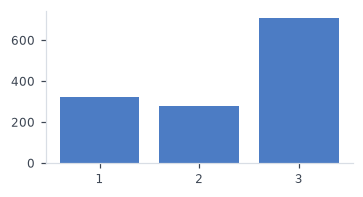
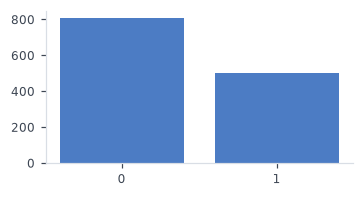
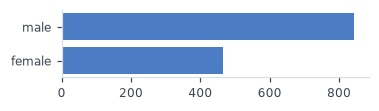
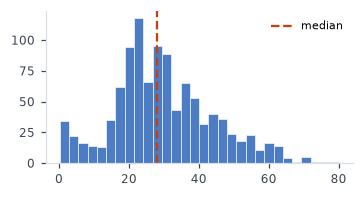
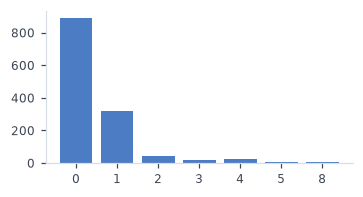
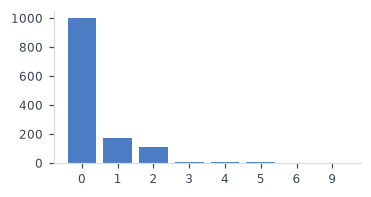
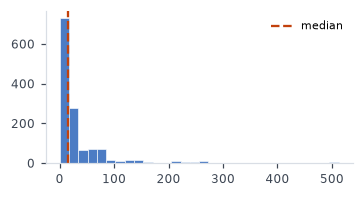
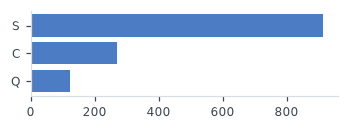
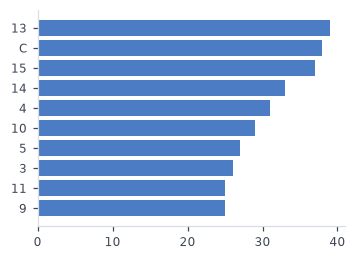
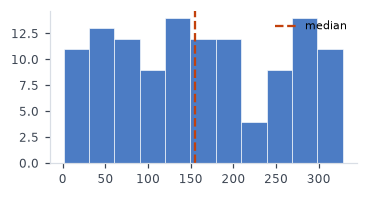
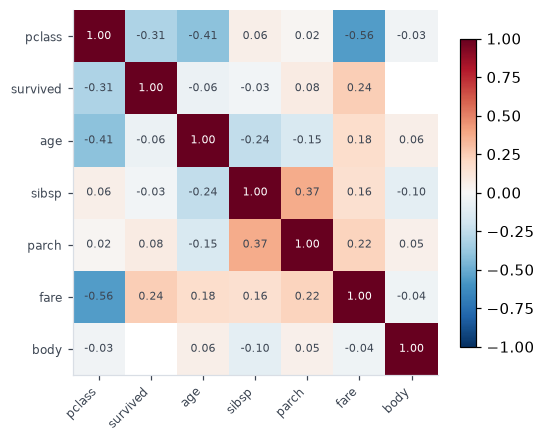

In [1]:
import pandas as pd

import dstoolkit as dst

raw = pd.read_csv('../data/titanic3.csv', na_values='?')
report = dst.profile(raw, title='Titanic passengers (raw)')
report

## The report as data

Everything in the report is also available programmatically: a summary table per column and the list of suggestions.

In [2]:
report.summary()

,type,dtype,non_missing,missing,missing_%,missing_expected,unique,outliers
column,,,,,,,,
pclass,numeric,int64,1309,0,0.0,False,3,NaN
survived,numeric,int64,1309,0,0.0,False,2,NaN
name,text,str,1309,0,0.0,False,1307,NaN
sex,categorical,str,1309,0,0.0,False,2,NaN
age,numeric,float64,1046,263,20.1,False,98,9.0
sibsp,numeric,int64,1309,0,0.0,False,7,NaN
parch,numeric,int64,1309,0,0.0,False,8,NaN
ticket,text,str,1309,0,0.0,False,929,NaN
fare,numeric,float64,1308,1,0.1,False,281,171.0


In [3]:
for s in report.suggestions:
    print(f"[{s.severity:>6}] {s.column or 'all rows'}: {s.message}")

[medium] cabin: 77% missing; too sparse to fill reliably. Drop it, or keep only a 'has value' flag.
[medium] boat: 63% missing; too sparse to fill reliably. Drop it, or keep only a 'has value' flag.
[medium] body: 91% missing; too sparse to fill reliably. Drop it, or keep only a 'has value' flag.
[  high] age: 263 missing (20.1%); fill with the median (robust to the skew and outliers).
[medium] fare: 1 missing (0.1%); fill with the median (robust to the skew and outliers).
[medium] embarked: 2 missing (0.2%); fill with the most common value.
[medium] fare: 171 values (13%) beyond 1.5×IQR with skew 4.4: a long right tail rather than a few outliers. A log scale suits it better than capping.
[   low] sex: Two categories; label-encode as 0/1 for modeling.
[   low] embarked: 3 categories; one-hot encode for modeling.
[   low] name: 1,307 distinct values: likely an identifier or free text. Leave it out of encoding and models.
[   low] ticket: 929 distinct values: likely an identifier or free

## Related columns

The report's "Related columns" section tests every pair of columns of any type (numbers, categories, or one of each) with `dst.associations()`, and keeps the pairs that are significant after correcting for testing many pairs at once. `report.associations` has them as a table:

In [4]:
report.associations[['column_1', 'column_2', 'test', 'measure', 'strength', 'n', 'note']].head(8).round(2)

,column_1,column_2,test,measure,strength,n,note
0,pclass,boat,ANOVA,eta,0.81,486,"7 of 27 groups have fewer than 5 values, which..."
1,pclass,fare,Spearman,rho,-0.71,1308,
2,fare,boat,ANOVA,eta,0.58,486,"7 of 27 groups have fewer than 5 values, which..."
3,survived,sex,ANOVA,eta,0.53,1309,
4,embarked,boat,chi-square,Cramér's V,0.46,484,"57% of expected counts are below 5, so the p-v..."
5,sibsp,fare,Spearman,rho,0.45,1308,
6,sibsp,parch,Spearman,rho,0.44,1309,
7,survived,boat,ANOVA,eta,0.42,486,"7 of 27 groups have fewer than 5 values, which..."


Each pair is tested on the rows where both values are present. So `survived` and `boat` are compared only for the 486 passengers with a lifeboat number, almost all of whom survived; the relation looks moderate here, but *whether* a boat is listed predicts survival almost perfectly, because it was recorded after the sinking. The [`Modelling_Titanic`](Modelling_Titanic.ipynb) notebook shows what that does to a model. The notes flag results that need care, such as lifeboats with only a few passengers.

## Apply the suggested code

`report.code()` writes the cleaning steps as one readable script, merging steps of the same kind into one call. Review it before running it: the suggestions are a starting point, not a decision.

In [5]:
print(report.code(df_name='df'))

import dstoolkit as dst

df = df.drop(columns=['cabin', 'boat', 'body'])
df = dst.fill_missing(df, numeric='median', columns=['age', 'fare'])
df = dst.fill_missing(df, categorical='most_frequent', columns=['embarked'])
df = dst.log_transform(df, ['fare'], suffix='_log')
df = dst.encode_categorical(df, {'sex': 'label', 'embarked': 'onehot'})


In [6]:
df = raw.copy()
exec(report.code(df_name='df'))

Filled missing values: age (263), fare (1)
Filled missing values: embarked (2)
Log-transformed ['fare'].
sex labels: female=0, male=1
Encoded sex (label), embarked (onehot).


## Profile again

The steps that were applied (dropping, filling, the log transform, encoding) no longer appear: the report recognises the new `fare_log`, `sex_label` and `embarked_*` columns. What remains is worth reading:

- **`age` now has outliers.** Filling 263 missing ages with one value (the median, 28) piles them up in the middle, which narrows the interquartile range, so more genuine ages fall outside 1.5×IQR. It's a side effect of single-value filling; `dst.fill_missing(numeric='knn')` estimates each missing age from similar passengers instead and avoids it.
- **`fare_log` still has 42 outliers, and they're real:** the 17 free tickets (a fare of £0) at the bottom, and 25 first-class fares of £227 or more at the top. The log scale tamed the tail without hiding them.
- **Free-text columns** (names, tickets, destinations) need a human decision rather than an automatic fix.

In [7]:
after = dst.profile(df, title='Titanic passengers (cleaned)')
for s in after.suggestions:
    print(f"[{s.severity:>6}] {s.column or 'all rows'}: {s.message}")

[medium] age: 101 outliers (8%) beyond 1.5×IQR; capping keeps the rows but limits their pull on averages and models.
[medium] fare_log: 42 outliers (3%) beyond 1.5×IQR; capping keeps the rows but limits their pull on averages and models.
[   low] name: 1,307 distinct values: likely an identifier or free text. Leave it out of encoding and models.
[   low] ticket: 929 distinct values: likely an identifier or free text. Leave it out of encoding and models.
[   low] home.dest: 369 distinct values: likely an identifier or free text. Leave it out of encoding and models.


In [8]:
print(f"Missing cells: {report.missing_cells:,} → {after.missing_cells:,}")
print(f"Columns: {report.n_columns} → {after.n_columns}")

Missing cells: 3,855 → 564
Columns: 14 → 16


## Validate: is the data what we expect?

A profile describes the data; `dst.validate()` checks it against rules you write, and reports every row that breaks one. Nothing is changed or converted. Here the rules say what a passenger record should look like:

In [9]:
rules = {
    "name": {"required": True, "type": "text"},
    "pclass": {"allowed": [1, 2, 3]},
    "survived": {"allowed": [0, 1]},
    "sex": {"allowed": ["male", "female"]},
    "age": {"required": True, "type": "integer", "min": 0, "max": 100},
    "fare": {"required": True, "min": 0.01},
    "embarked": {"required": True, "allowed": ["S", "C", "Q"]},
}
check = dst.validate(raw, rules)

Validated 1,309 rows against 13 rule(s): 5 failed (318 row(s)).
  age: type (integer) failed for 45 row(s), e.g. row 1 = 0.92; row 173 = 32.5; row 222 = 28.5
  age: required (no blanks) failed for 263 row(s), e.g. row 15 = missing; row 37 = missing; row 40 = missing
  fare: required (no blanks) failed for 1 row(s), e.g. row 1225 = missing
  fare: min (≥ 0.01) failed for 17 row(s), e.g. row 7 = 0; row 70 = 0; row 125 = 0
  embarked: required (no blanks) failed for 2 row(s), e.g. row 168 = missing; row 284 = missing


Each failure is a question, not an instruction:

- **Missing `age`, `fare` and `embarked`** are the gaps the profile already found.
- **`age` isn't always a whole number.** Some ages are fractions: infants' ages in months, and some ages that end in .5. Here the rule is what's wrong, not the data, so `"type": "integer"` should go.
- **17 passengers paid a fare of 0.** That could be an error or a real free ticket; it needs checking against the source, not filling.

`check.failures()` lists every failing value with the reason, and `raw.loc[check.failing_index]` gives the rows themselves:

In [10]:
check.failures(rule="min").head()

,row,column,rule,value,reason
0,7,fare,min,0.0,below the minimum 0.01
1,70,fare,min,0.0,below the minimum 0.01
2,125,fare,min,0.0,below the minimum 0.01
3,150,fare,min,0.0,below the minimum 0.01
4,170,fare,min,0.0,below the minimum 0.01


Validating the cleaned data shows what the cleaning fixed, and what it rightly left alone:

In [11]:
after_check = dst.validate(df, rules)

Validated 1,309 rows against 13 rule(s): 2 failed (62 row(s)).
  age: type (integer) failed for 45 row(s), e.g. row 1 = 0.92; row 173 = 32.5; row 222 = 28.5
  fare: min (≥ 0.01) failed for 17 row(s), e.g. row 7 = 0; row 70 = 0; row 125 = 0


## Prepare for a model

Naming the column a model will predict adds a **Target** section: the class balance, how strongly each feature is related to survival, blanks that are related to it, and possible leaks.

In [12]:
model_report = dst.profile(raw, title='Titanic passengers: predicting survival', target='survived', charts=False)
model_report.target.leaks

['boat']

In [13]:
model_report.target.missingness[['column_2', 'measure', 'strength']].round(2)

,column_2,measure,strength
0,boat,Cramér's V,0.95
1,cabin,Cramér's V,0.30
2,body,Cramér's V,0.25
3,home.dest,Cramér's V,0.20
4,age,Cramér's V,0.10


`boat` is flagged because whether it's blank predicts survival almost perfectly: lifeboat numbers were recorded for the people who got into a boat. A model given that column would score well in testing and be useless for a passenger whose fate is unknown.

The statistics can't catch everything. `body` (a body identification number) only exists for people who died, so it's a leak too, but so few bodies were recovered that its blanks look only moderately related to survival (0.25). The report lists it under blanks related to the target and asks whether each was known before the outcome: that's a human decision.

`pipeline()` writes a leak-free starter: steps that learn nothing from the data run before the split, and steps that learn from it run inside a scikit-learn pipeline, refitted on each training fold.

In [14]:
print(model_report.pipeline())

import dstoolkit as dst
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.pipeline import make_pipeline

# 1. Steps that learn nothing from the data: safe before the split
df = dst.log_transform(df, ['fare'])   # log(1 + x) learns nothing from the data
# Blanks related to the target: add a flag only if the blank was known before the outcome
# df['cabin_missing'] = df['cabin'].isna().astype(int)
# df['body_missing'] = df['body'].isna().astype(int)
# df['home.dest_missing'] = df['home.dest'].isna().astype(int)
# df['age_missing'] = df['age'].isna().astype(int)

# 2. Features and target
# Left out (possible leaks: check they were known before the outcome): boat
# Left out (suggested for dropping): cabin, body
# Left out (identifiers or free text): name, ticket, home.dest
X = df[['pclass', 'sex', 'age', 'sibsp', 'parch', 'fare', 'embarked']]
y = df['survived']

# 3. Steps that learn from the data: i

In [15]:
df = raw.copy()
exec(model_report.pipeline())

Log-transformed ['fare'].


roc_auc: 0.856 ± 0.014


The flags for informative blanks are commented out on purpose: `body_missing` would be a leak. Whether to use another one, such as `age_missing`, depends on why the ages are missing. If some were filled in from records compiled after the sinking, the blanks would leak too. The script leaves that call to you.

## Share it

`save()` writes a single self-contained HTML file (charts included) that opens in any browser. Passing `rules=` adds the validation results as a section of the report, and `target=` adds the Target section.

In [16]:
report = dst.profile(raw, title='Titanic passengers (raw)', rules=rules, target='survived')
report.save('../docs/titanic_profile.html')

PosixPath('../docs/titanic_profile.html')